In [30]:
# %matplotlib ipympl
import numpy as np
import matplotlib.pyplot as plt
import tqdm

from session_data import *
from visualize import *
from antenna_array import *
from mikrotik_metadata import *

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [47]:
session_dir = Path("../data/2025-11-20/session_135938")
elevation_angle = np.deg2rad(3)
theta_range = np.deg2rad([-95, 95])

session = SessionData.from_directory(session_dir, channel=2)
session.load_all_router_batches()

channel_data = session.get_csi_data(averaged=False)
channel_data_avg = session.get_csi_data(averaged=True)

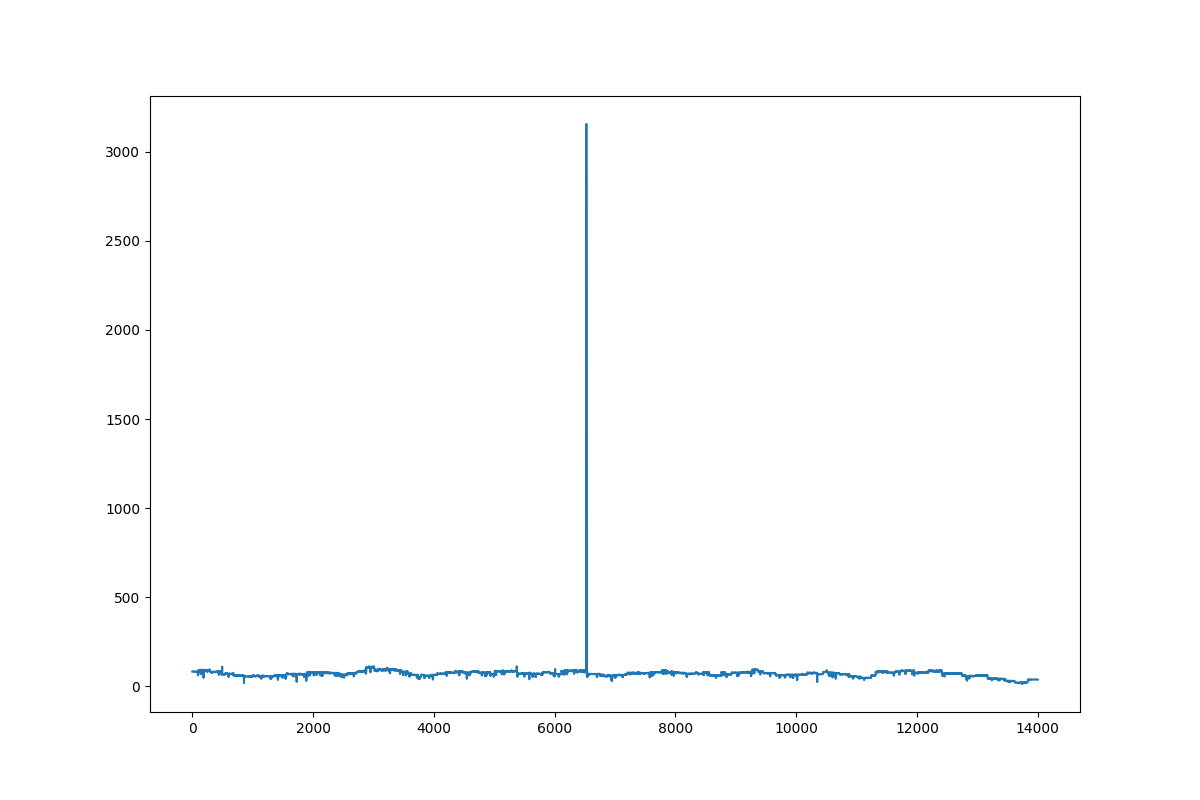

In [48]:
plt.figure(figsize=(12, 8))
plt.plot(np.abs(channel_data[:, 0]))
plt.show()


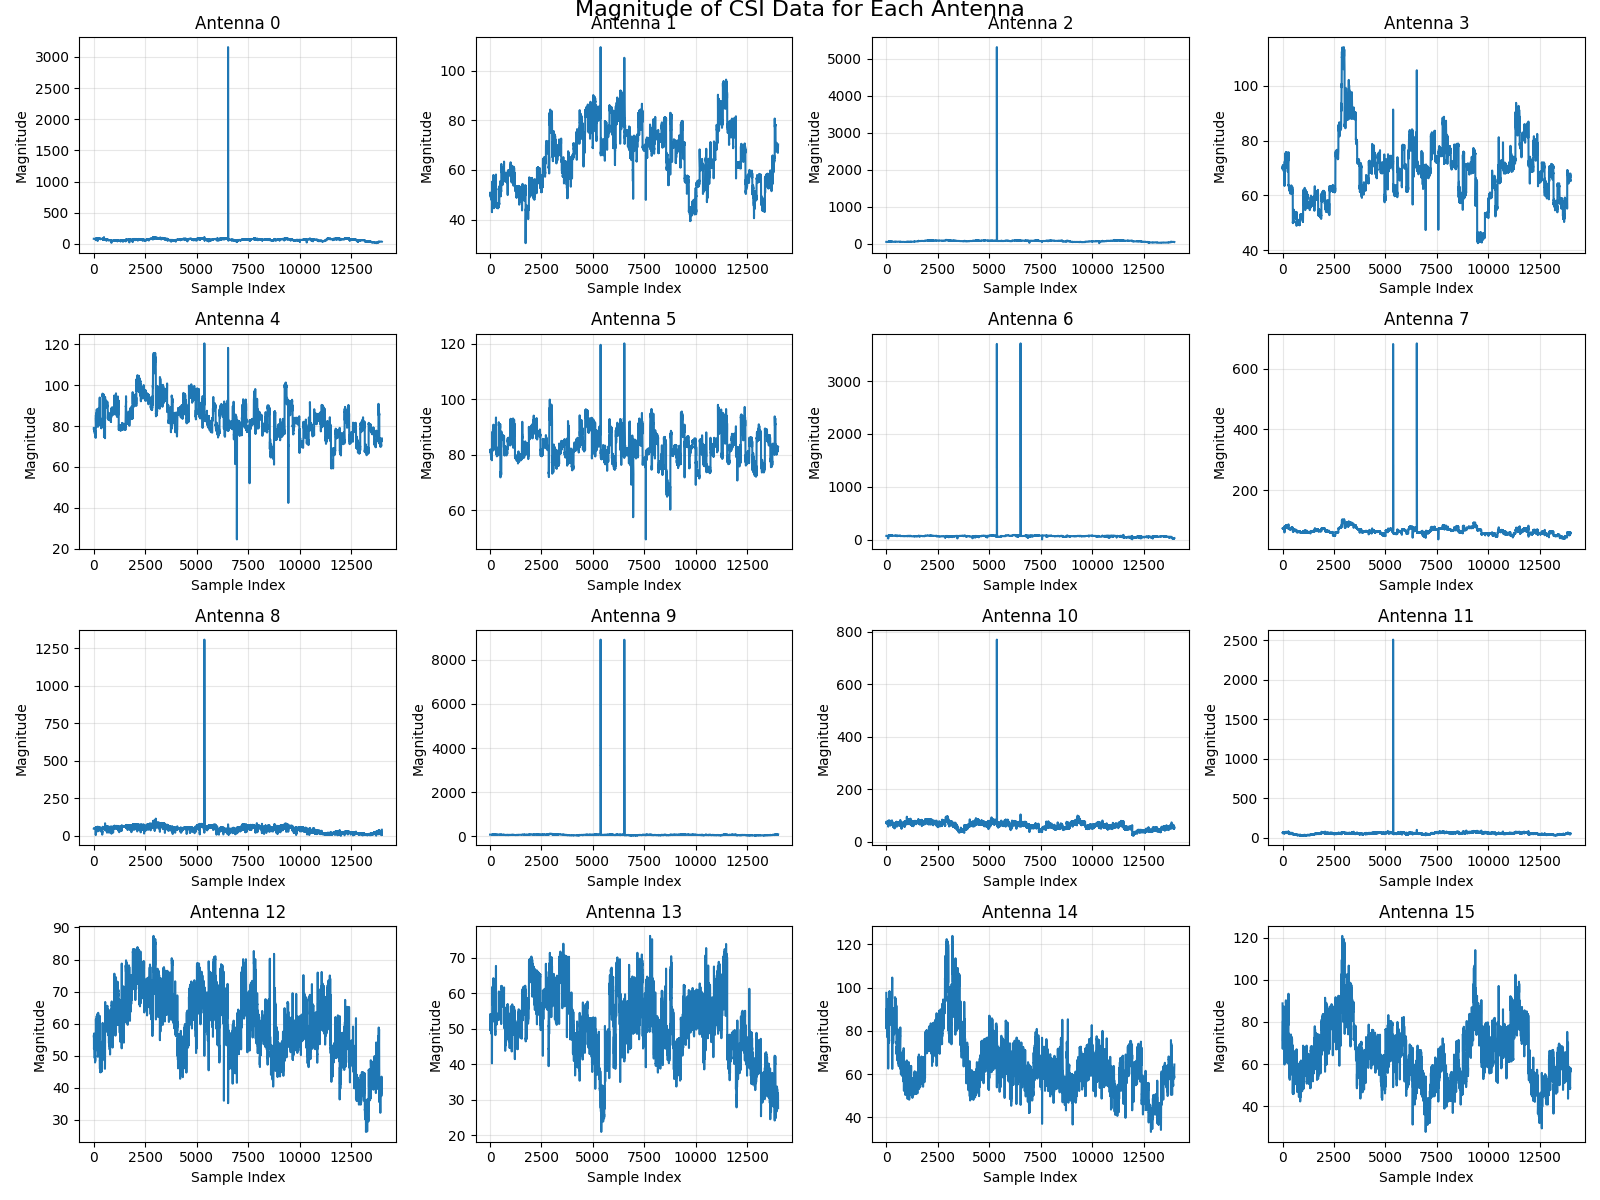

In [49]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for i in range(16):
    ax = axes[i//4, i%4]
    ax.plot(np.abs(channel_data[:, i]))
    ax.set_title(f'Antenna {i}')
    ax.set_xlabel('Sample Index')
    ax.set_ylabel('Magnitude')
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.suptitle('Magnitude of CSI Data for Each Antenna', fontsize=16, y=1.00)
plt.show()


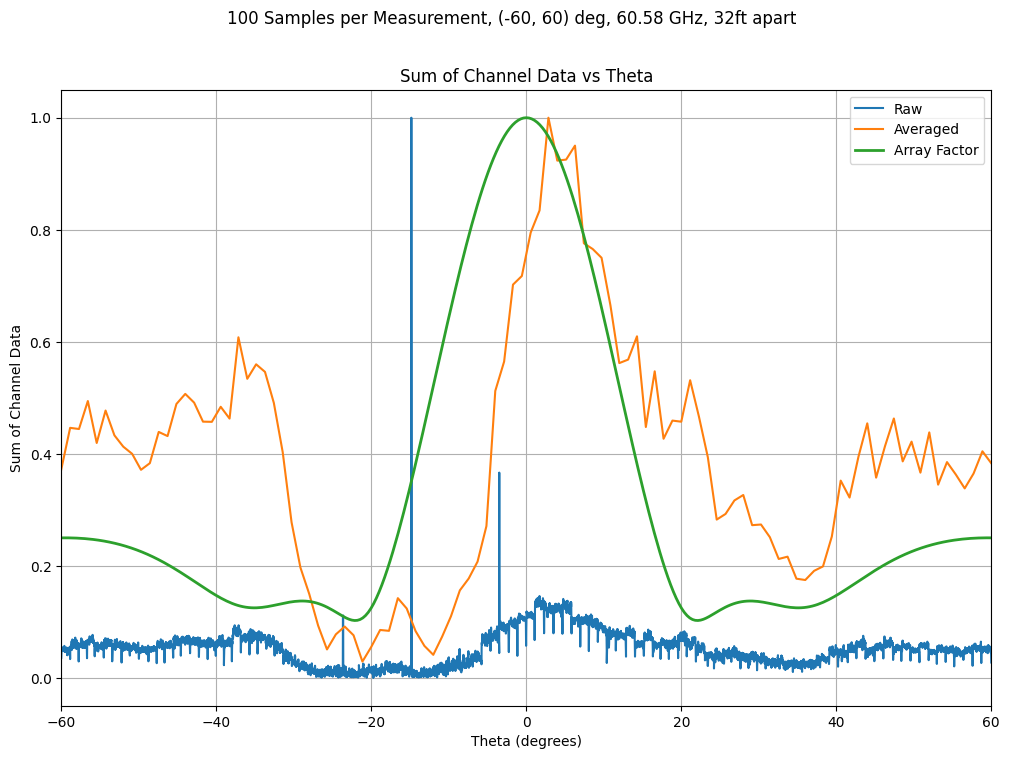

In [44]:
theta_range_avg = np.linspace(np.deg2rad(-60), np.deg2rad(60), len(channel_data_avg))
theta_range = np.linspace(np.deg2rad(-60), np.deg2rad(60), len(channel_data))

spacing = 0.58 * session.frequency / 60.48
antenna_array = AntennaArray()
antenna_array_boresight = AntennaArray()
for ant in range(32):
    if ant not in valid_antennas:
        continue
    antenna_array.add_element(ordering_sets[ant, 0]*spacing - np.sign(ordering_sets[ant, 0])*spacing/2, 
            0, ordering_sets[ant, 1]*spacing - np.sign(ordering_sets[ant, 1])*spacing/2)
    antenna_array_boresight.add_element(ordering_sets[ant, 0]*spacing - np.sign(ordering_sets[ant, 0])*spacing/2, 
            0, ordering_sets[ant, 1]*spacing - np.sign(ordering_sets[ant, 1])*spacing/2)

antenna_array_boresight.set_weights(antenna_array_boresight.get_conjugate_beamformer(0, 0))
af, az, _ = antenna_array_boresight.get_array_pattern_azimuth(0, 1024, full=True)

raw_sum = np.sum(np.clip(channel_data, np.min(channel_data), 120), axis=1)
avg_sum = np.sum(channel_data_avg, axis=1)

plt.figure(figsize=(12, 8))
plt.plot(np.rad2deg(theta_range), np.abs(raw_sum) / np.max(np.abs(raw_sum)), label='Raw')
plt.plot(np.rad2deg(theta_range_avg), np.abs(avg_sum) / np.max(np.abs(avg_sum)), label='Averaged')
plt.plot(np.rad2deg(az), np.abs(af) / np.max(np.abs(af)), label='Array Factor', linewidth=2)
plt.grid()
plt.xlim(-60, 60)
plt.xlabel('Theta (degrees)')
plt.ylabel('Sum of Channel Data')
plt.title('Sum of Channel Data vs Theta')
plt.suptitle('100 Samples per Measurement, (-60, 60) deg, 60.58 GHz, 32ft apart')
plt.legend()
plt.show()

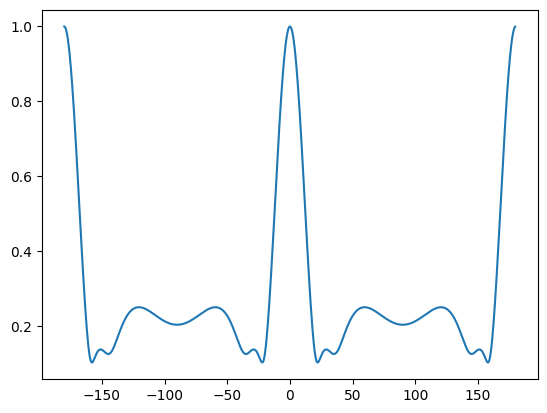

In [11]:
plt.figure()
plt.plot(np.rad2deg(az), np.abs(af) / np.max(np.abs(af)))

(<Figure size 800x600 with 1 Axes>,
 <Axes: xlabel='x (in λ)', ylabel='z (in λ)'>)

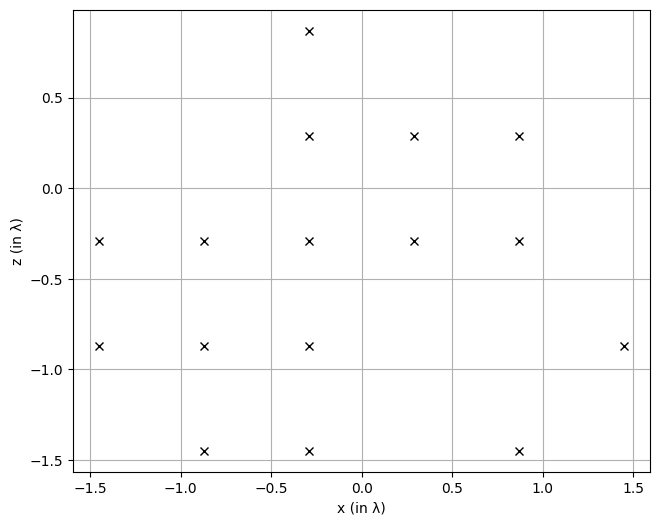

In [12]:
antenna_array_boresight.show_2d()

<>:28: SyntaxWarning: invalid escape sequence '\p'
<>:28: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_6347/677735356.py:28: SyntaxWarning: invalid escape sequence '\p'
  plt.title('Array Factor @ ($\\theta = 0, \phi = 0$) * Array Factor @ ($\\theta, \phi$) from all samples (each 100 samples are averaged)')


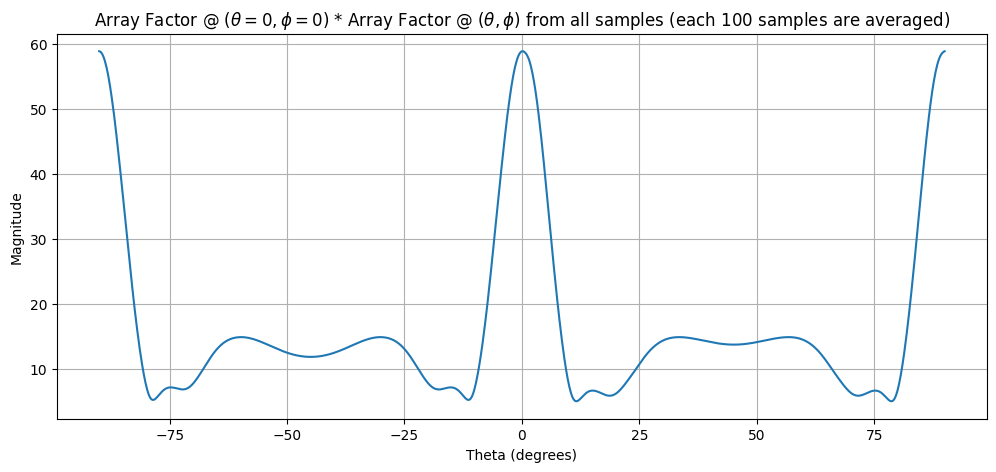

In [8]:
spacing = 0.58 * session.frequency / 60.48
antenna_array = AntennaArray()
antenna_array_boresight = AntennaArray()
for ant in range(32):
    if ant not in valid_antennas:
        continue
    antenna_array.add_element(ordering_sets[ant, 0]*spacing - np.sign(ordering_sets[ant, 0])*spacing/2, 
            0, ordering_sets[ant, 1]*spacing - np.sign(ordering_sets[ant, 1])*spacing/2)
    antenna_array_boresight.add_element(ordering_sets[ant, 0]*spacing - np.sign(ordering_sets[ant, 0])*spacing/2, 
            0, ordering_sets[ant, 1]*spacing - np.sign(ordering_sets[ant, 1])*spacing/2)

antenna_array_boresight.set_weights(antenna_array_boresight.get_conjugate_beamformer(0, 0))
af, _, _ = antenna_array_boresight.get_array_pattern_azimuth(0, 1024, full=True)

theta_vals = np.linspace(-np.pi/2, np.pi/2, 1024)
result = np.zeros(len(theta_vals))

for i in range(len(channel_data_avg)):
    antenna_array.set_weights(np.conjugate(channel_data_avg[i, :]))
    array_response, _, _ = antenna_array.get_array_pattern_azimuth(0, 1024, full=True)
    result += np.abs(array_response * af)

plt.figure(figsize=(12, 5))
plt.plot(np.rad2deg(theta_vals), np.abs(result) / len(channel_data_avg))
plt.grid()
plt.xlabel('Theta (degrees)')
plt.ylabel('Magnitude')
plt.title('Array Factor @ ($\\theta = 0, \phi = 0$) * Array Factor @ ($\\theta, \phi$) from all samples (each 100 samples are averaged)')
plt.show()


<>:28: SyntaxWarning: invalid escape sequence '\p'
<>:28: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Kanishka\AppData\Local\Temp\ipykernel_23388\3205440734.py:28: SyntaxWarning: invalid escape sequence '\p'
  plt.title('Array Factor @ ($\\theta = 0, \phi = 0$) * Array Factor @ ($\\theta, \phi$) from all samples')
100%|██████████| 9034/9034 [01:57<00:00, 76.70it/s]


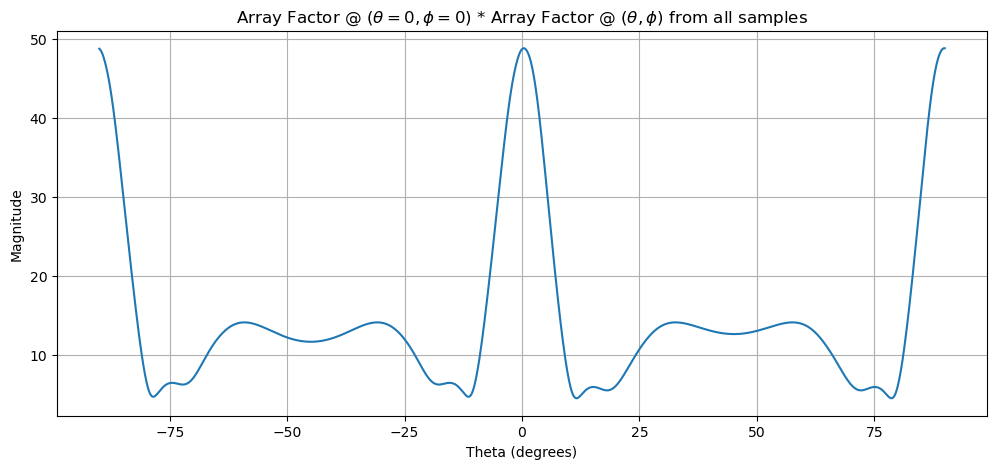

In [33]:
spacing = 0.58 * session.frequency / 60.48
antenna_array = AntennaArray()
antenna_array_boresight = AntennaArray()
for ant in range(32):
    if ant not in valid_antennas:
        continue
    antenna_array.add_element(ordering_sets[ant, 0]*spacing - np.sign(ordering_sets[ant, 0])*spacing/2, 
            0, ordering_sets[ant, 1]*spacing - np.sign(ordering_sets[ant, 1])*spacing/2)
    antenna_array_boresight.add_element(ordering_sets[ant, 0]*spacing - np.sign(ordering_sets[ant, 0])*spacing/2, 
            0, ordering_sets[ant, 1]*spacing - np.sign(ordering_sets[ant, 1])*spacing/2)

antenna_array_boresight.set_weights(antenna_array_boresight.get_conjugate_beamformer(0, 0))
af, _, _ = antenna_array_boresight.get_array_pattern_azimuth(0, 1024, full=True)

theta_vals = np.linspace(-np.pi/2, np.pi/2, 1024)
result = np.zeros(len(theta_vals))

for i in tqdm.trange(len(channel_data)):
    antenna_array.set_weights(np.conjugate(channel_data[i, :]))
    array_response, _, _ = antenna_array.get_array_pattern_azimuth(0, 1024, full=True)
    result += np.abs(array_response * af)

plt.figure(figsize=(12, 5))
plt.plot(np.rad2deg(theta_vals), np.abs(result) / len(channel_data))
plt.grid()
plt.xlabel('Theta (degrees)')
plt.ylabel('Magnitude')
plt.title('Array Factor @ ($\\theta = 0, \phi = 0$) * Array Factor @ ($\\theta, \phi$) from all samples')
plt.show()
